In [114]:
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
import numpy as np
from EDX import *
from utils import *
from utils_sofima import *
import hyperspy.api as hs
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import copy
from importlib import reload
from sklearn.preprocessing import MinMaxScaler

from skimage import data, img_as_float, feature
import tensorstore as ts
from scipy.stats import pearsonr
from datetime import datetime
import warnings
import pickle
from datetime import datetime
import pickle

from itertools import repeat
import random
import logging
import exspy
import tifffile as tf
from kmeans_hungarian import *

### Load 100-frame datset

In [3]:
with open(f'/Volumes/Microscopy4/results/preprocessed_edx/20260114_062341_tile_aligned_100frames_align2zero.pkl', 'rb') as file:    # I should re-align these later
    tile_ref = pickle.load(file)

tile_ref.apply("crop", parameters = {"crop_idx": (slice(50,tile_ref.EDX_dim[0]-50),slice(50,tile_ref.EDX_dim[1]-50),slice(None,None,None))})
tile_ref.apply("binning", parameters={"dim": (974,974,250)})
tile_ref.apply("MeanFilterEDX", parameters={"kernel_size": 3})


<EM_EDX | 6 steps logged>

### Load denoised 20-frame dataset

In [124]:
with open(f'/Volumes/Microscopy4/results/preprocessed_edx/20251201_142554_tile_aligned_20frames.pkl', 'rb') as file:    # I should re-align these later
    tile_noisy = pickle.load(file)

tile_noisy.apply("crop", parameters = {"crop_idx": (slice(50,tile_noisy.EDX_dim[0]-50),slice(50,tile_noisy.EDX_dim[1]-50),slice(None,None,None))})
tile_noisy.apply("binning", parameters={"dim": (974,974,250)})
tile_noisy.apply("MeanFilterEDX", parameters={"kernel_size": 3})

<EM_EDX | 6 steps logged>

### Load denoised datasets

In [126]:
tiles_denoised = []
tiles_denoised.append(tile_noisy)

In [127]:
# Directory containing EMD files 
denoised_dir = "/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma"


file_paths =[]
for x in os.listdir(denoised_dir):
    if x.endswith('.pkl') and os.path.basename(x).startswith('._') is False:
        file_paths.append(os.path.join(denoised_dir,x))

print(file_paths)

for file_path in file_paths:
    with open(file_path, 'rb') as file:    # I should re-align these later
        tiles_denoised.append(pickle.load(file))

# add ref tile at the end 
tiles_denoised.append(tile_ref)


# set names
names = ['Noisy','NGMeet 0.1','NGMeet 0.2','NGMeet 0.3','NGMeet 0.4','NGMeet 0.5','NGMeet 0.6','NGMeet 0.7','100 frames']

['/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.10.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.20.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.30.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.40.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.50.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.60.pkl', '/Volumes/Microscopy4/results/preprocessed_edx/aligned20_NGMeet_varying_Sigma/NGMeet_0.70.pkl']


## Visual inspection

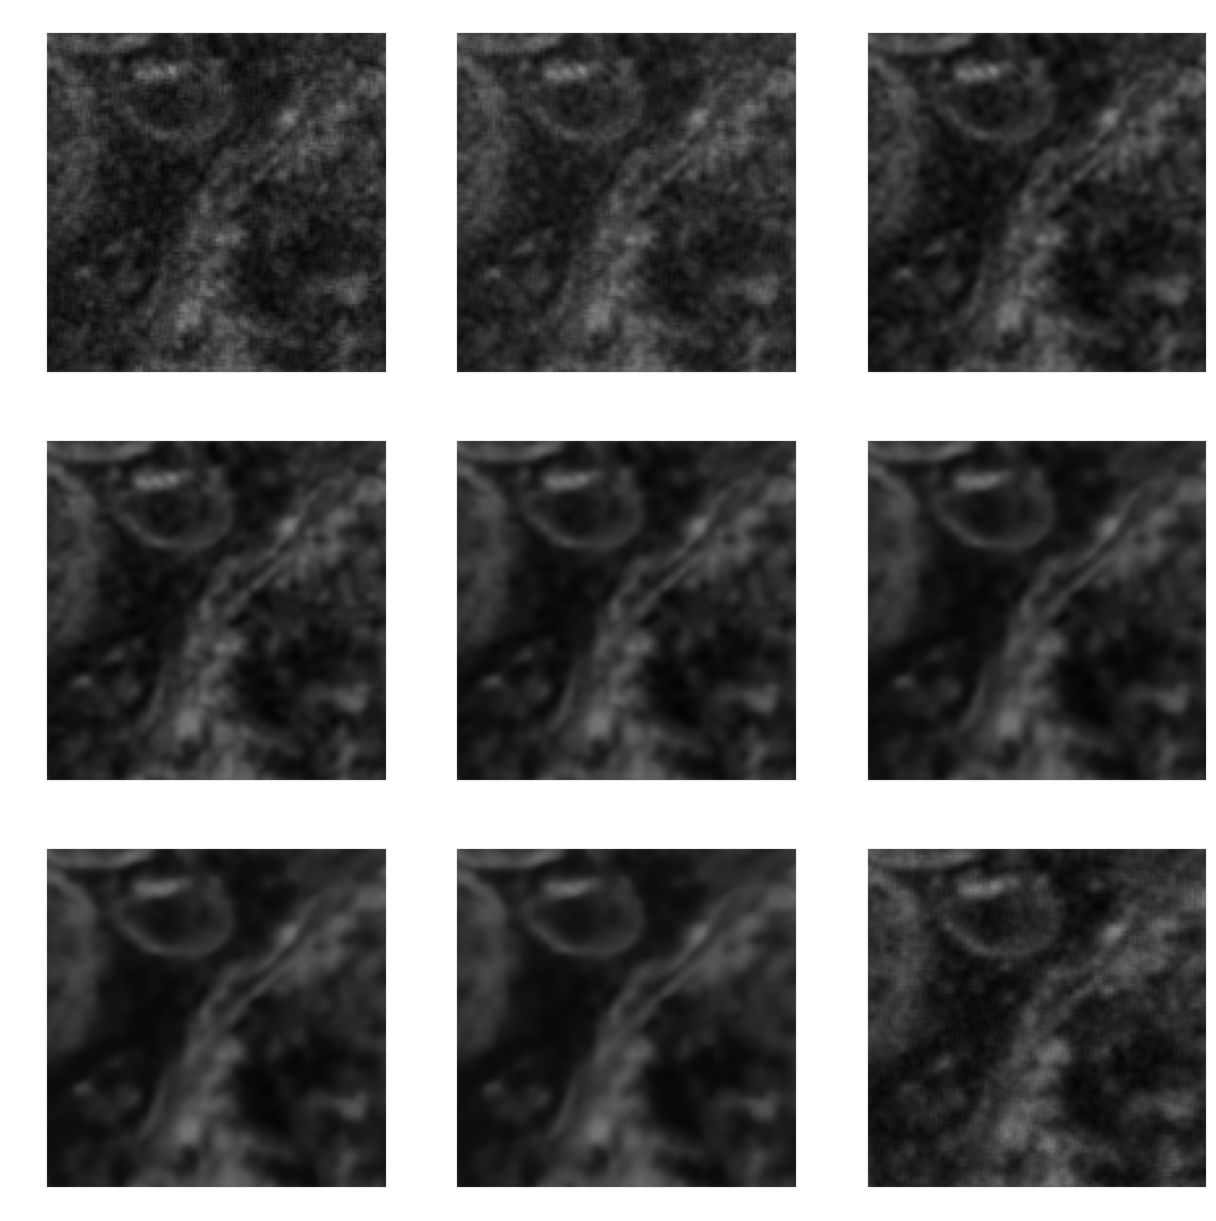

In [160]:
f, axs = plt.subplots(3,3, figsize=(15,15))

zoom = (slice(800,930),slice(650,780))

#zoom = (slice(None),slice(None))

#zoom = (slice(350,550),slice(150,350))


for cnt, ax in enumerate(axs.ravel()):
    ax.imshow(tiles_denoised[cnt].FalseColor([25,25,25])[zoom])
    ax.set_title(names[cnt])

plt.close()
make_dark_presentation(f,text_color='white', line_width=2.5, transparent=True)

### Compute SSIM with the reference 

In [131]:
SSIM_all = []

for tile in tiles_denoised:
    SSIM_all.append(np.asarray(eval_ssim3(MinMax(tile_ref.EDX),MinMax(tile.EDX))))
    
    

### Visualize 

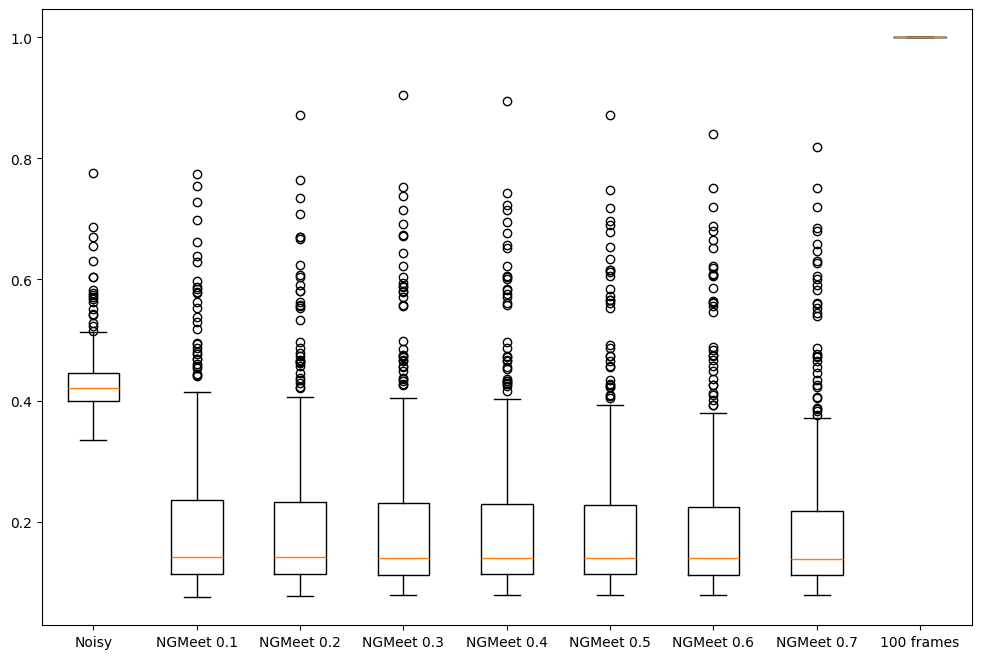

In [132]:
f, ax = plt.subplots(figsize=(12,8))

ax.boxplot(np.vstack(SSIM_all).transpose(),tick_labels=names)
plt.show()

#plt.close()
#make_dark_presentation(f,text_color='white', line_width=2.5, transparent=True)

## Import and show masks

bool (974, 974) [False  True]
bool (974, 974) [False  True]
bool (974, 974) [False  True]
bool (974, 974) [False  True]


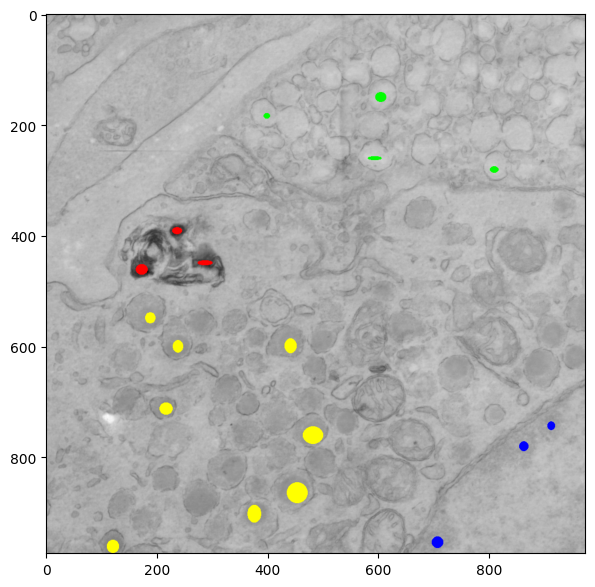

In [133]:
mask_dir = '/Users/aj/Desktop/work/PostDoc_UMCG/work/analysis/EDX_Project/PreHyperspectralEDX/data/masks_classification'

mask_paths = []
for x in os.listdir(mask_dir):
    if x.endswith('.tif') and os.path.basename(x).startswith('._') is False:
        mask_paths.append(os.path.join(mask_dir,x))


masks = np.zeros((974,974,4),dtype=bool)
for cnt, mask_path in enumerate(mask_paths):
    img = tf.imread(mask_path)[25:1024-25,25:1024-25].astype(bool)
    print(img.dtype,img.shape,np.unique(img))
    masks[:,:,cnt] = img


grey = tiles_denoised[0].haadf
overlayed_image = np.dstack((1-grey, 1-grey, 1-grey))
overlayed_image = Normalize_uint8(overlayed_image)

colors = [[255,0,0],[255,255,0],[0,255,0],[0,0,255]]

for i in range(masks.shape[2]):
    overlayed_image[np.where(masks[:,:,i])[0],np.where(masks[:,:,i])[1],:] = colors[i]

f, ax = plt.subplots(figsize=(7,7))
ax.imshow(Normalize_uint8(overlayed_image))



## Kmeans clustering 

In [134]:
from sklearn.cluster import KMeans

# create the ground truth array for the classification
labels_gt_og = np.zeros((974*974),dtype='uint8')
for i in range(masks.shape[2]):
    mask_flat = masks[:,:,i].reshape((-1,))
    labels_gt_og[np.where(mask_flat)] = i+1


# remove the non-masked area
labels_gt = label_gt_og[np.where(labels_gt_og)]

# convert back to 0 to n-1
labels_gt = labels_gt-1



In [143]:
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix

num_labels = len(np.unique(labels_gt))
accuracies = []

for tile in tiles_denoised:
    X = tile.EDX_2D[np.where(label_gt_og)[0],:]
    kmeans = KMeans(n_clusters = 4, random_state=666)
    kmeans.fit(X)
    labels = kmeans.labels_ 
    
    #################################
    cm = confusion_matrix(labels_gt, labels, labels=range(num_labels)) # gets the confusion matrix
    #print("---------------------\nold confusion matrix:\n" \
    #      " %s\naccuracy: %.2f" % (str(cm), accuracy(cm)))

    cost_matrix = make_cost_matrix(labels, labels_gt)

    m = Munkres()
    indexes = m.compute(cost_matrix)
    mapper = { old: new for (old, new) in indexes }

    new_labels = translate_clustering(labels, mapper)
    new_cm = confusion_matrix(labels_gt, new_labels, labels=range(num_labels))

    print("---------------------\nnew confusion matrix:\n" \
          " %s\naccuracy: %.2f" % (str(new_cm), accuracy(new_cm)))

    accuracies.append(accuracy(new_cm))


---------------------
new confusion matrix:
 [[ 712    3    0    0]
 [   0 2562  106 1959]
 [   0   10  511  157]
 [   0   37  371  355]]
accuracy: 0.61
---------------------
new confusion matrix:
 [[ 713    2    0    0]
 [   0 3043   54 1530]
 [   0    2  526  150]
 [   0   38  298  427]]
accuracy: 0.69
---------------------
new confusion matrix:
 [[ 714    1    0    0]
 [   0 4016   24  587]
 [   0    2  449  227]
 [   0   42  182  539]]
accuracy: 0.84
---------------------
new confusion matrix:
 [[ 714    1    0    0]
 [   0 4263   14  350]
 [   0    2  451  225]
 [   0   44  137  582]]
accuracy: 0.89
---------------------
new confusion matrix:
 [[ 714    1    0    0]
 [   0 4322   16  289]
 [   0    1  540  137]
 [   0   32  115  616]]
accuracy: 0.91
---------------------
new confusion matrix:
 [[ 715    0    0    0]
 [   0 4367   18  242]
 [   0    0  593   85]
 [   0   28   91  644]]
accuracy: 0.93
---------------------
new confusion matrix:
 [[ 715    0    0    0]
 [   0 4393   

### Evaluate blur

In [148]:
from skimage.measure import blur_effect

blur_effect_list = []

for tile, name in zip(tiles_denoised, names):
    be = blur_effect(tile.EDX[:,:,25], h_size=11)
    blur_effect_list.append(be)
    print(name, be)

Noisy 0.2779906012070287
NGMeet 0.1 0.3008102039143424
NGMeet 0.2 0.3389062943280834
NGMeet 0.3 0.3861567352114567
NGMeet 0.4 0.4320441902063971
NGMeet 0.5 0.4649655536077868
NGMeet 0.6 0.48827263298322454
NGMeet 0.7 0.504901966709684
100 frames 0.3775688574914904


### Visualize accuracies and blur

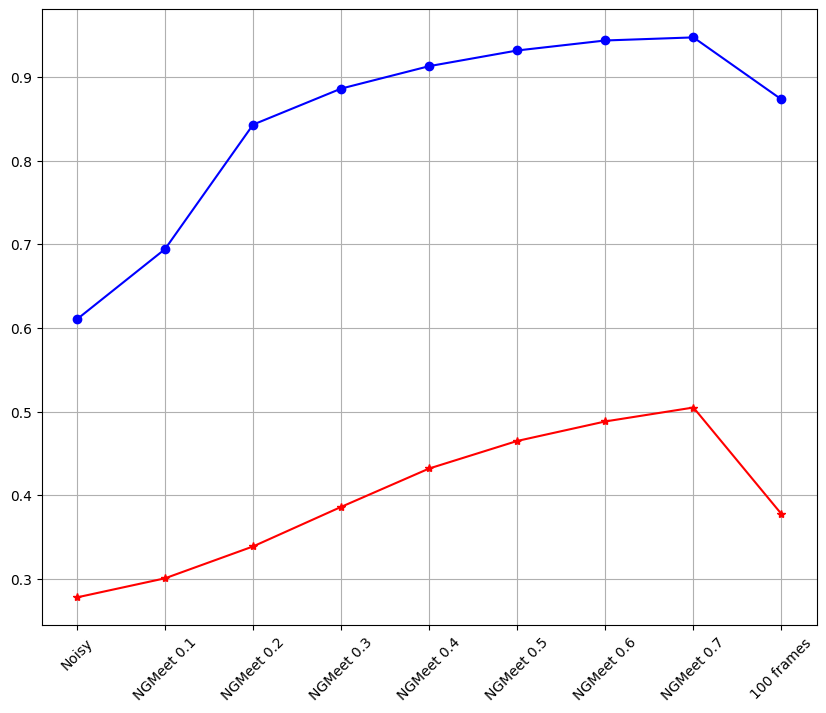

In [154]:
f, ax = plt.subplots(figsize=(10,8))
ax.plot(names, accuracies,'bo-')
ax.plot(names, blur_effect_list,'r*-')
ax.tick_params(axis='x', labelrotation=45)
ax.grid(True)